# 07 — Eleven chords and live feedback

Added B, Bm, Dm and F: 132 recordings total. Notebook 05 keeps the earlier seven-chord exercise. This notebook reads the current results without retraining.

To reproduce from the project root, run `python -m src.personal_dataset`, then `python -m src.train_personal`. These create WAV copies, extract the same 12 features, split 99/33 by chord and technique, evaluate, then fit the app model on all 132 recordings.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
reports = root / "reports/personal_11"
metadata = pd.read_csv(reports / "metadata.csv")
display(pd.crosstab(metadata.chord, metadata.technique))
metrics = json.loads((reports / "metrics.json").read_text())
print(f"Validation accuracy: {metrics['accuracy']:.1%}")
display(pd.DataFrame(metrics["macro avg"], index=["Macro average"]))

technique,downstrum,fast_strum,repeated_strumming,slow_picking
chord,,,,
A,4,0,4,4
Am,4,0,4,4
B,0,4,4,4
Bm,0,4,4,4
C,4,0,4,4
D,4,0,4,4
Dm,0,4,4,4
E,4,0,4,4
Em,4,0,4,4


Validation accuracy: 81.8%


,precision,recall,f1-score,support
Macro average,0.848485,0.818182,0.825108,33.0


## Which chords got confused?

There are only three validation recordings per chord. Use the table to identify examples to listen to, rather than treating the score as a precise generalisation estimate. The final app model includes these validation recordings in training; fresh recordings are needed to evaluate that model.

,filepath,chord,technique,prediction
0,data/processed/marcus_recordings/D/Nytt opptak...,D,downstrum,Dm
11,data/processed/marcus_recordings/Dm/Nytt oppta...,Dm,slow_picking,D
12,data/processed/marcus_recordings/G/Nytt opptak...,G,repeated_strumming,D
18,data/processed/marcus_recordings/Em/Nytt oppta...,Em,downstrum,E
25,data/processed/marcus_recordings/D/Nytt opptak...,D,repeated_strumming,Dm
26,data/processed/marcus_recordings/Dm/Nytt oppta...,Dm,repeated_strumming,D


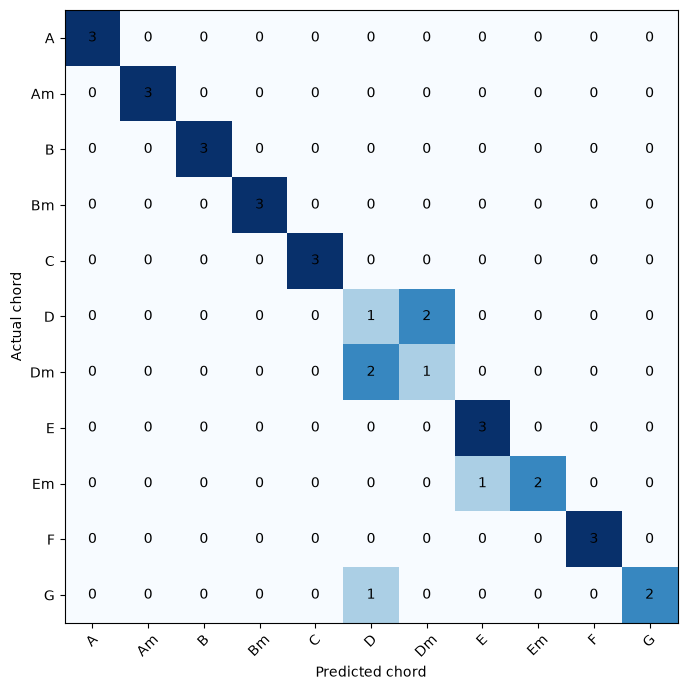

In [2]:
results = pd.read_csv(reports / "validation_predictions.csv")
display(results[results.chord != results.prediction])
confusion = pd.read_csv(reports / "confusion_matrix.csv", index_col=0)
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(confusion, cmap="Blues", vmin=0, vmax=3)
ax.set_xticks(range(len(confusion)), confusion.columns, rotation=45)
ax.set_yticks(range(len(confusion)), confusion.index)
ax.set_xlabel("Predicted chord")
ax.set_ylabel("Actual chord")
for row in range(len(confusion)):
    for column in range(len(confusion)):
        ax.text(column, row, str(confusion.iloc[row, column]), ha="center", va="center")
plt.tight_layout()
plt.show()

## Try live feedback

Run `python app.py` from the project root and start the live microphone. Audio is accumulated in a rolling three-second buffer, with updates requested twice per second. The newest score receives 60% weight and the previous smoothed score 40%. This reduces flicker but adds delay. Quiet chunks clear the buffer; other noises can still be classified as chords.

The headset has not yet been tested interactively with this eleven-chord model. Start with slow chord changes, then see how quickly the prediction catches up. Record mistakes and delays rather than replaying until correct.